# (1) import libraries

In [1]:
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D

import numpy as np
from scipy.stats import multivariate_normal
from IPython.display import clear_output

import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)

Using device: cpu


# (2) data preparation

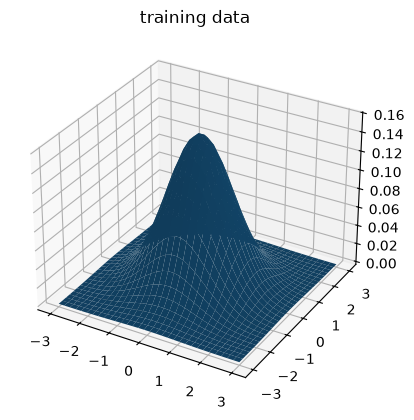

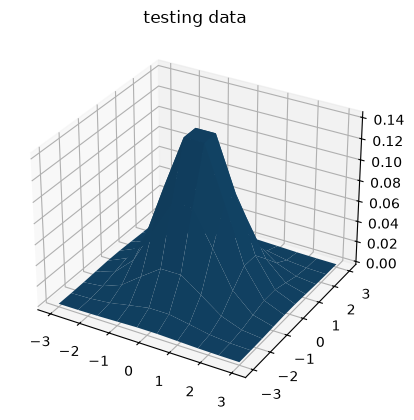

In [2]:
# Training ------------------------------
A_grid = 32j
x1, x2 = np.mgrid[-3.0:3.0:A_grid, -3.0:3.0:A_grid]
x1x2 = np.column_stack([x1.flat, x2.flat])

mu = np.array([0.0, 0.0])
covariance = np.diag([1.0, 1.0])

y = multivariate_normal.pdf(x1x2, mean=mu, cov=covariance)
y = y.reshape(x1.shape)

x_train = x1x2.astype(np.float32)
y_train = y.flatten().astype(np.float32)

fig = plt.figure()
ax = fig.add_subplot(111, projection="3d")
ax.plot_surface(x1, x2, y)
plt.title("training data")
plt.show()

# Testing -------------------------------
A_test_grid = 10j
x1_t, x2_t = np.mgrid[-3.0:3.0:A_test_grid, -3.0:3.0:A_test_grid]
x1x2_t = np.column_stack([x1_t.flat, x2_t.flat])

y_t = multivariate_normal.pdf(x1x2_t, mean=mu, cov=covariance)
y_t = y_t.reshape(x1_t.shape)

x_test = x1x2_t.astype(np.float32)
y_test = y_t.flatten().astype(np.float32)

fig = plt.figure()
ax = fig.add_subplot(111, projection="3d")
ax.plot_surface(x1_t, x2_t, y_t)
plt.title("testing data")
plt.show()

x_train_tensor = torch.from_numpy(x_train)
y_train_tensor = torch.from_numpy(y_train).unsqueeze(1)
x_test_tensor = torch.from_numpy(x_test).to(device)
y_test_tensor = torch.from_numpy(y_test).unsqueeze(1).to(device)

# (3) MLP

In [3]:
class GaussMLP(nn.Module):
    def __init__(self, B=16):
        super().__init__()
        self.fc = nn.Linear(2, B)
        self.act1 = nn.Sigmoid()
        self.gauss_apxm = nn.Linear(B, 1)
        self.act2 = nn.Sigmoid()

    def forward(self, x):
        h = self.act1(self.fc(x))
        out = self.act2(self.gauss_apxm(h))
        return out

def train_and_eval(x_sub, y_sub, x_val, y_val, B=16, epochs=100, batch_size=128, lr=0.01):
    model = GaussMLP(B=B).to(device)
    criterion = nn.MSELoss()
    optimizer = torch.optim.SGD(model.parameters(), lr=lr)

    dataset = TensorDataset(x_sub, y_sub)
    loader = DataLoader(dataset, batch_size=batch_size, shuffle=True)

    for _ in range(epochs):
        model.train()
        for bx, by in loader:
            bx, by = bx.to(device), by.to(device)
            optimizer.zero_grad()
            preds = model(bx)
            loss = criterion(preds, by)
            loss.backward()
            optimizer.step()

    model.eval()
    with torch.no_grad():
        train_mse = criterion(model(x_train_tensor.to(device)), y_train_tensor.to(device)).item()
        test_mse = criterion(model(x_val), y_val).item()
    return train_mse, test_mse

# (4) training and evaluating MLP

### (4.1) Number of training samples (A) (no. of hidden nodes (B) = 16 and no. of epochs (C) = 100)

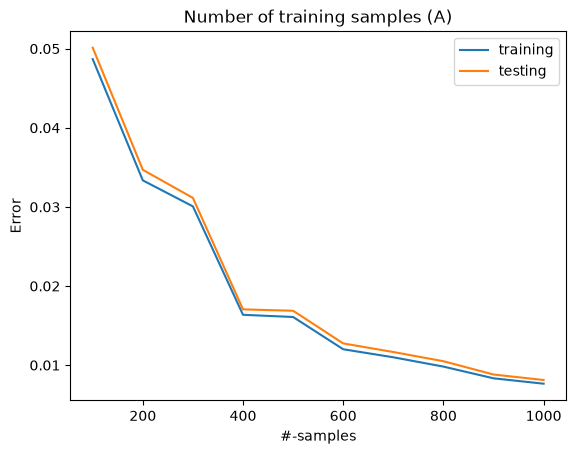

In [4]:
train_error = []
test_error = []
max_pool = min(1001, len(x_train))
A_array = []

B = 16
C = 100
for A in np.arange(100, max_pool, 100):
    sel_indx = np.random.choice(np.arange(1, max_pool), size=int(A), replace=False)
    tr_err, te_err = train_and_eval(
        x_train_tensor[sel_indx], y_train_tensor[sel_indx],
        x_test_tensor, y_test_tensor,
        B=B, epochs=C, batch_size=128, lr=0.01
    )
    train_error.append(tr_err)
    test_error.append(te_err)
    A_array.append(int(A))

    clear_output(wait=True)
    plt.plot(A_array, train_error, label="training")
    plt.plot(A_array, test_error, label="testing")
    plt.legend()
    plt.title("Number of training samples (A)")
    plt.xlabel("#-samples")
    plt.ylabel("Error")
    plt.show()

### (4.2) Number of hidden nodes (B) (no. of training samples (A) = 800 and no. of epochs (C) = 100)

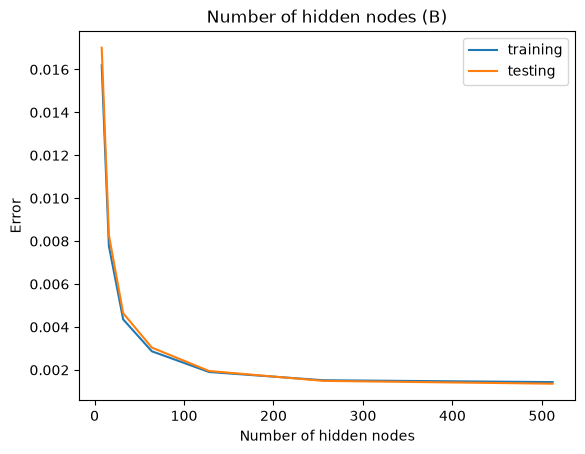

In [5]:
train_error = []
test_error = []
B_array = []
max_pool = min(1001, len(x_train))

A = 800
B = 8
C = 100
while B <= 512:
    sel_indx = np.random.choice(np.arange(1, max_pool), size=A, replace=False)
    tr_err, te_err = train_and_eval(
        x_train_tensor[sel_indx], y_train_tensor[sel_indx],
        x_test_tensor, y_test_tensor,
        B=B, epochs=C, batch_size=128, lr=0.01
    )
    train_error.append(tr_err)
    test_error.append(te_err)
    B_array.append(B)

    clear_output(wait=True)
    plt.plot(B_array, train_error, label="training")
    plt.plot(B_array, test_error, label="testing")
    plt.legend()
    plt.title("Number of hidden nodes (B)")
    plt.xlabel("Number of hidden nodes")
    plt.ylabel("Error")
    plt.show()

    B *= 2

### (4.3) Number of epochss (C) (no. of training samples (A) = 800 and no. of hidden nodes (B) = 128)

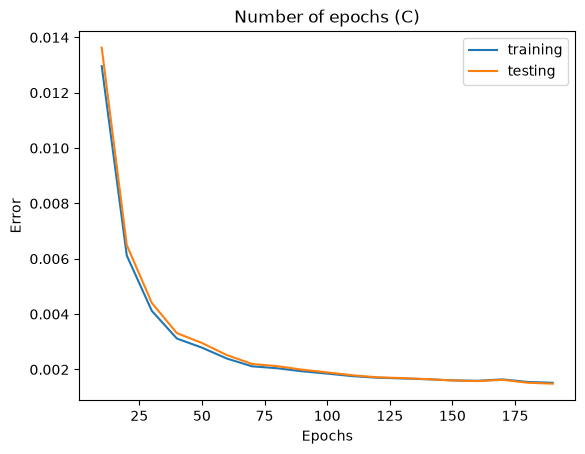

In [6]:
train_error = []
test_error = []
max_pool = min(1001, len(x_train))
C_array = []

A = 800
B = 128
for C in np.arange(10, 200, 10):
    sel_indx = np.random.choice(np.arange(1, max_pool), size=A, replace=False)
    tr_err, te_err = train_and_eval(
        x_train_tensor[sel_indx], y_train_tensor[sel_indx],
        x_test_tensor, y_test_tensor,
        B=B, epochs=int(C), batch_size=128, lr=0.01
    )
    train_error.append(tr_err)
    test_error.append(te_err)
    C_array.append(int(C))

    clear_output(wait=True)
    plt.plot(C_array, train_error, label="training")
    plt.plot(C_array, test_error, label="testing")
    plt.legend()
    plt.title("Number of epochs (C)")
    plt.xlabel("Epochs")
    plt.ylabel("Error")
    plt.show()